# Lab Assignment 11: Coreference Resolution & Question Answering

**Objective:**
In this lab you will implement and evaluate two core NLP tasks:
(A) **Coreference Resolution** using a SpanBERT-based model, and
(B) **Question Answering** by fine-tuning BERT on the SQuAD reading comprehension dataset.
You will also explore the connection between the two tasks.

**Task:** (A) Coreference chain detection and evaluation. (B) Span extraction from a passage given a question.

**Learning outcomes:**
1. Understand and use a SpanBERT-based coreference model.
2. Implement B-cubed evaluation for coreference.
3. Fine-tune (or use a fine-tuned) BERT model for span-based QA.
4. Implement SQuAD-style EM and F1 evaluation.
5. Explore the Open-Domain QA retriever-reader pipeline.

| Part | Topic | Points |
|---|---|---|
| 1 | Setup & Data | 5 |
| 2 | Coreference: SpanBERT Model | 20 |
| 3 | Coreference: Manual Analysis & Evaluation | 20 |
| 4 | Question Answering: BERT for SQuAD | 25 |
| 5 | QA Evaluation: EM and F1 | 15 |
| 6 | Open-Domain QA Pipeline | 10 |
| 7 | Connecting Coref and QA | 5 |
| | **Total** | **100** |

**Submission:** Complete all `# TODO` sections and all markdown answers. Run **Kernel > Restart & Run All** before submitting.


---
## Theory Recap

**Coreference Resolution** groups all text spans (mentions) that refer to the same real-world entity.
Three types of mentions: *pronouns*, *named entities*, and *noun phrases*.

**Mention-Ranking** scores each mention against all preceding candidates:
$$s(i,j) = s_m(i) + s_m(j) + s_a(i,j)$$
A dummy antecedent ε allows the model to start a new cluster.

**SpanBERT** represents span (i,j) as: $g(i,j) = [h_i, h_j, \tilde{h}(i,j), \phi(i,j)]$

**BERT for QA (SQuAD):** Fine-tune with two linear classifiers on the final hidden states:
$$P_{start}(i) = \text{softmax}(W_{start}\, h_i), \quad P_{end}(i) = \text{softmax}(W_{end}\, h_i)$$
The predicted answer is $P[\text{argmax}(P_{start}) : \text{argmax}(P_{end})+1]$.


**B-cubed Precision/Recall** for mention $m$:
$$P_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{sys}(m)|}, \quad R_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{gold}(m)|}$$


---
## Part 1: Setup and Data (5 points)

### 1.1 Install and Import Libraries


In [1]:
# 1.1 Install required libraries
!pip install -q fastcoref transformers datasets evaluate scikit-learn spacy matplotlib
!python -m spacy download en_core_web_sm -q
print('Libraries installed ✅')

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Libraries installed ✅


In [2]:
import re, string, random
from collections import Counter

import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import pipeline, AutoTokenizer, AutoModelForQuestionAnswering
from fastcoref import FCoref
from datasets import load_dataset

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Imports done and seeds set ✅')

Imports done and seeds set ✅


### 1.2 Test Texts for Coreference
Use the following texts for Parts 2 and 3. **Do not change them.**


In [3]:
TEXT_1 = (
    'Akhila met Prajwal at the local park. '
    "Akhila's son Akash was just two months younger than her son Prajwal. "
    'She resigned herself to make Akash the best tree in the play. '
    'She bought him a brown T-shirt to represent the trunk.'
)

TEXT_2 = (
    'Barack Obama was born in Hawaii. '
    'He served as the 44th President of the United States. '
    'Obama attended Columbia University. '
    'His presidency lasted from 2009 to 2017.'
)

TEXT_3 = (
    'Maria Curie was a Polish-born physicist and chemist. '
    'She was the first woman to win a Nobel Prize. '
    'In 1906 she became the first woman professor at the University of Paris. '
    'Curie discovered polonium and radium with her husband Pierre.'
)

print('Sample texts loaded.')

Sample texts loaded.


---
## Part 2: Coreference Resolution using SpanBERT (20 points)

### 2.1 Load the Model and Run Prediction
Load the `FCoref` model and run coreference resolution on **TEXT_1**, **TEXT_2**, and **TEXT_3**.
Print the coreference clusters (as strings) for each text.


In [4]:
# --- Compatibility patch (from the tutorial): fastcoref 2.1.6 vs transformers 5.x ---
import fastcoref.modeling as _fc_modeling
if not getattr(_fc_modeling.FCorefModel, '_patched_post_init', False):
    _orig_init = _fc_modeling.FCorefModel.__init__
    def _patched_init(self, *args, **kwargs):
        _orig_init(self, *args, **kwargs)
        if not hasattr(self, 'all_tied_weights_keys'):
            self.post_init()
    _fc_modeling.FCorefModel.__init__ = _patched_init
    _fc_modeling.FCorefModel._patched_post_init = True

# --- 2.1 Load FCoref and run on the three texts ---
model = FCoref(device='cpu')
preds = model.predict(texts=[TEXT_1, TEXT_2, TEXT_3])

for i, (text, pred) in enumerate(zip([TEXT_1, TEXT_2, TEXT_3], preds)):
    print(f'--- Text {i+1} ---')
    for cluster in pred.get_clusters(as_strings=True):
        print(' → '.join(cluster))
    print()

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

Inference:   0%|          | 0/3 [00:00<?, ?it/s]

--- Text 1 ---
Akhila → Akhila's → her → She → herself → She
Prajwal → her son Prajwal
Akhila's son Akash → Akash → him

--- Text 2 ---
Barack Obama → He → Obama → His

--- Text 3 ---
Maria Curie → She → she → Curie → her



In [5]:
GOLD_ENTITY_T1 = {
    'akhila': 'Akhila', "akhila's": 'Akhila', 'her': 'Akhila', 'she': 'Akhila',
    'akash': 'Akash', 'him': 'Akash', "akhila's son akash": 'Akash',
    'prajwal': 'Prajwal', 'her son prajwal': 'Prajwal', 'her son': 'Prajwal',
}
GOLD_T1_MENTIONS = ['Akhila', "Akhila's", 'her', 'She', 'Akash', 'him', 'Prajwal']

sys_t1 = preds[0].get_clusters(as_strings=True)
found = set()
print('Model clusters for TEXT_1 with the gold entity of every mention:')
for c in sys_t1:
    labels = [GOLD_ENTITY_T1.get(m.lower().strip(), '?') for m in c]
    known = set(l for l in labels if l != '?')
    status = 'PURE ✅' if len(known) <= 1 else 'MIXED ❌ (false-positive links)'
    print(f'  {list(zip(c, labels))}  → {status}')
    found.update(m.lower().strip() for m in c)

missed = [m for m in GOLD_T1_MENTIONS if m.lower() not in found]
print('\nGold mentions NOT placed in any cluster (false negatives):', missed if missed else 'none')
unk = sorted({m for c in sys_t1 for m in c if m.lower().strip() not in GOLD_ENTITY_T1})
print('Extra spans predicted that are not in the gold list (check manually):', unk if unk else 'none')

Model clusters for TEXT_1 with the gold entity of every mention:
  [('Akhila', 'Akhila'), ("Akhila's", 'Akhila'), ('her', 'Akhila'), ('She', 'Akhila'), ('herself', '?'), ('She', 'Akhila')]  → PURE ✅
  [('Prajwal', 'Prajwal'), ('her son Prajwal', 'Prajwal')]  → PURE ✅
  [("Akhila's son Akash", 'Akash'), ('Akash', 'Akash'), ('him', 'Akash')]  → PURE ✅

Gold mentions NOT placed in any cluster (false negatives): none
Extra spans predicted that are not in the gold list (check manually): ['herself']


### 2.2 Markdown Questions
Answer in the cell below:
1. For TEXT_1, list all the coreference clusters the model found. Are they correct?
2. Which mentions were **missed** (false negatives) and which were **wrong** (false positives)?
3. Why might the model confuse 'her son' in TEXT_1? What linguistic phenomenon makes this hard?


**Your answers:**

1. **Clusters found for TEXT_1** (all three are correct):
   - Akhila → Akhila's → her → She → herself → She  (the person Akhila)
   - Prajwal → her son Prajwal  (the child Prajwal)
   - Akhila's son Akash → Akash → him  (the child Akash, who becomes the tree)

   The model resolved all pronouns correctly, including the possessive *Akhila's / her*, the reflexive *herself* and the object pronoun *him* (→ Akash). Non-referring singleton noun phrases (*the local park*, *the best tree*, *the play*, *a brown T-shirt*, *the trunk*) are correctly left out because they are singletons.

2. **False negatives / false positives.** There are **no false negatives**: every gold mention (Akhila, Akhila's, her, She, She, Akash, him, Prajwal, her son Prajwal) is placed in a cluster. There are **no false positives**: every cluster is pure, and no two entities were merged (Akash and Prajwal were kept apart). The only differences from a strict gold annotation are at **span level**: the model uses the longer span *"Akhila's son Akash"* instead of just *"Akash"* (a mention-boundary difference, though the cluster itself is correct), and it also includes the reflexive *herself*, which is a valid coreferent of Akhila.

3. **Why 'her son' is hard.** (i) **Same-gender distractors:** *Akash* and *Prajwal* are both male and both described as Akhila's sons, so *her son* and *him* have two equally plausible male antecedents and the model needs discourse and world knowledge to choose. (ii) **Nested / possessive mentions:** *her son Prajwal* is a noun phrase that *contains* the pronoun *her*; the inner mention (*her* → Akhila) and the outer mention (*her son Prajwal* → Prajwal) refer to different entities. (iii) **Parallel structure:** "Akhila's son Akash … her son Prajwal" repeats the relational noun *son*, so syntax and gender cues are not enough. The underlying phenomenon is **anaphora resolution with possessive pronouns and nested/appositive noun phrases**. In this text SpanBERT handled it correctly, but this is where such models most often fail.

### 2.3 Mention Detection: Types and Counts
Write a function `count_mention_types(text)` that uses spaCy to count the number of:
- Pronouns (using POS tags)
- Named entities (using NER)
- Noun phrases (using noun chunks)
Apply it to all three texts. Print results in a table.


In [6]:
import spacy
nlp = spacy.load('en_core_web_sm')

def count_mention_types(text):
    """
    Returns a dict: {'pronouns': int, 'named_entities': int, 'noun_phrases': int}
    """
    doc = nlp(text)
    pronouns = [tok for tok in doc if tok.pos_ == 'PRON']      # pronouns via POS tags
    named_entities = list(doc.ents)                             # named entities via NER
    noun_phrases = list(doc.noun_chunks)                        # noun phrases via noun chunks
    return {
        'pronouns': len(pronouns),
        'named_entities': len(named_entities),
        'noun_phrases': len(noun_phrases),
    }

for i, text in enumerate([TEXT_1, TEXT_2, TEXT_3], 1):
    counts = count_mention_types(text)
    print(f'Text {i}: {counts}')

# Results in a table
print()
print(f"{'Text':<8}{'Pronouns':>10}{'Named Entities':>16}{'Noun Phrases':>14}")
print('-' * 48)
for i, text in enumerate([TEXT_1, TEXT_2, TEXT_3], 1):
    c = count_mention_types(text)
    print(f"{'Text '+str(i):<8}{c['pronouns']:>10}{c['named_entities']:>16}{c['noun_phrases']:>14}")

Text 1: {'pronouns': 5, 'named_entities': 5, 'noun_phrases': 15}
Text 2: {'pronouns': 2, 'named_entities': 7, 'noun_phrases': 8}
Text 3: {'pronouns': 3, 'named_entities': 8, 'noun_phrases': 15}

Text      Pronouns  Named Entities  Noun Phrases
------------------------------------------------
Text 1           5               5            15
Text 2           2               7             8
Text 3           3               8            15


---
## Part 3: Manual Evaluation with B-cubed (20 points)

### 3.1 Gold Standard Clusters (TEXT_2 Only)
For TEXT_2, define the **gold standard** coreference clusters using the mention offsets from the text.
The character-level mentions are given — use them as entity labels (strings).


In [7]:
# Gold clusters for TEXT_2 (mention strings as identifiers)
GOLD_TEXT2 = [
    {'Barack Obama', 'He', 'Obama', 'His'},  # Cluster 1: the person
    {'the United States'},                    # Cluster 2: the country
    {'Columbia University'},                  # Cluster 3: the university
    {'Hawaii'},                               # Singleton: Hawaii
]
# Note: singletons are valid gold clusters too
print('Gold clusters defined:', len(GOLD_TEXT2), 'clusters')

Gold clusters defined: 4 clusters


### 3.2 Extract System Clusters for TEXT_2
Extract the coreference clusters that the model predicted for TEXT_2 (from Part 2.1).
Convert them to sets of mention strings (as above) for comparison.


In [8]:
# 3.2 System clusters for TEXT_2 (from the predictions in Part 2.1), as sets of mention strings
system_clusters_text2 = [set(cluster) for cluster in preds[1].get_clusters(as_strings=True)]
print(system_clusters_text2)

[{'He', 'His', 'Barack Obama', 'Obama'}]


### 3.3 Implement and Compute B-cubed
Implement the `bcubed(gold_clusters, system_clusters)` function and compute B-cubed P, R, F1 for TEXT_2.


In [9]:
def bcubed(gold_clusters, system_clusters):
    """
    Compute B-cubed Precision, Recall, F1.
    Arguments:
        gold_clusters:   list of sets of mention strings (gold standard)
        system_clusters: list of sets of mention strings (system output)
    Returns: (precision, recall, f1) — all floats rounded to 3 decimal places
    """
    # 1. mention -> cluster lookups
    gold_map = {m: i for i, c in enumerate(gold_clusters) for m in c}
    sys_clusters = [set(c) for c in system_clusters]
    sys_map = {m: i for i, c in enumerate(sys_clusters) for m in c}

    # Gold mentions that the system did not cluster (it drops singletons) are treated
    # as singleton system clusters, which is the standard convention.
    for m in gold_map:
        if m not in sys_map:
            sys_clusters.append({m})
            sys_map[m] = len(sys_clusters) - 1

    # 2. per-mention precision and recall
    p_total, r_total = 0.0, 0.0
    mentions = list(gold_map)
    for m in mentions:
        g_c = set(gold_clusters[gold_map[m]])
        s_c = sys_clusters[sys_map[m]]
        overlap = len(g_c & s_c)
        p_total += overlap / len(s_c)
        r_total += overlap / len(g_c)

    # 3. average over mentions, 4. F1
    P = p_total / len(mentions)
    R = r_total / len(mentions)
    F1 = 2 * P * R / (P + R) if (P + R) > 0 else 0.0
    return round(P, 3), round(R, 3), round(F1, 3)

# Compute B-cubed for TEXT_2
P, R, F1 = bcubed(GOLD_TEXT2, system_clusters_text2)
print(f'B-cubed for TEXT_2: P={P}, R={R}, F1={F1}')

B-cubed for TEXT_2: P=1.0, R=1.0, F1=1.0


### 3.4 Short Questions
1. What does it mean when B-cubed Precision is 1.0 but Recall is low?
2. What does it mean when B-cubed Recall is 1.0 but Precision is low?
3. Besides B-cubed, name two other standard coreference evaluation metrics used for OntoNotes.


**Your answers:**

1. **Precision = 1.0 but Recall low:** every mention the system put together really does belong together (its clusters are *pure*), but the system is too conservative: it **splits** one true entity chain into several smaller clusters or leaves mentions unlinked, so many gold coreference links are missed (under-merging, e.g. putting *Obama* and *He* in different clusters).

2. **Recall = 1.0 but Precision low:** the system finds every gold link, but only because it **over-merges**: it lumps mentions of different entities into big clusters (in the extreme, all mentions in one cluster gives R = 1.0), so each mention's predicted cluster contains many wrong mentions and precision falls.

3. **Other standard metrics for OntoNotes:** **MUC** (link-based) and **CEAF** (entity-based, CEAFφ4 / CEAFe). Also used: BLANC and LEA; the official **CoNLL-2012 score** is the average F1 of MUC, B³ and CEAFφ4.

---
## Part 4: Question Answering with BERT (25 points)

### 4.1 Setup the QA Model
Load `deepset/bert-base-cased-squad2` using HuggingFace `AutoTokenizer` and `AutoModelForQuestionAnswering`.


In [10]:
# 4.1 Load the QA model
model_name = 'deepset/bert-base-cased-squad2'
tokenizer  = AutoTokenizer.from_pretrained(model_name)
qa_model   = AutoModelForQuestionAnswering.from_pretrained(model_name)
qa_model.eval()
print('QA model loaded ✅')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

QA model loaded ✅


### 4.2 Implement Span Extraction
Implement `extract_answer(question, context, tokenizer, model)` that:
1. Tokenizes the (question, context) pair.
2. Runs the model.
3. Finds the best valid span: `start <= end` and both within the context tokens.
4. Returns the answer string and its score (start_logit[s] + end_logit[e]).


In [11]:
import torch

def _best_span(start_logits, end_logits, context_idx, max_answer_len=50):
    """Best valid span (s, e) among context token positions: e >= s and e - s < max_answer_len."""
    best_score, best_s, best_e = float('-inf'), None, None
    for s in context_idx:
        for e in context_idx:
            if e < s:
                continue                      # enforce end >= start
            if e - s >= max_answer_len:
                break                         # enforce end - start < max_answer_len
            score = start_logits[s] + end_logits[e]
            if score > best_score:
                best_score, best_s, best_e = score, s, e
    return best_score, best_s, best_e

def extract_answer(question, context, tokenizer, model, max_answer_len=50):
    """
    Extract answer span from context given a question.
    Returns:
        answer: str — the extracted answer text
        score:  float — start_logit[s] + end_logit[e]
    """
    # 1. Tokenise the (question, context) pair
    inputs = tokenizer(question, context, return_tensors='pt',
                       truncation='only_second', max_length=512,
                       return_offsets_mapping=True)
    offsets = inputs.pop('offset_mapping')[0].tolist()
    seq_ids = inputs.sequence_ids(0)          # None for [CLS]/[SEP], 0 = question, 1 = context

    # 2. Forward pass (no gradients)
    with torch.no_grad():
        outputs = model(**inputs)
    start_logits = outputs.start_logits[0].tolist()
    end_logits   = outputs.end_logits[0].tolist()

    # 3. Only context tokens are valid answer positions (excludes question, [CLS], [SEP])
    context_idx = [i for i, sid in enumerate(seq_ids) if sid == 1]
    if not context_idx:
        return '', float('-inf')

    score, s, e = _best_span(start_logits, end_logits, context_idx, max_answer_len)

    # 4. Map the token span back to the original context string
    start_char, end_char = offsets[s][0], offsets[e][1]
    # expand to whole-word boundaries (avoids partial-word answers such as 'urie' for 'Curie')
    while start_char > 0 and context[start_char - 1].isalnum():
        start_char -= 1
    while end_char < len(context) and context[end_char].isalnum():
        end_char += 1
    answer = context[start_char:end_char].strip()
    return answer, float(score)

### 4.3 Test on SQuAD-Style Examples
Test your function on the following (passage, question, gold_answer) triples. Print the predicted answer and score.


In [12]:
squad_examples = [
    {
        'context':  'The Tesla family moved to Gospic in 1862, where Tesla father worked as a pastor. '
                    'Nikola completed Primary School and then the Lower Real Gymnasium.',
        'question': 'Where did the Tesla family move in 1862?',
        'gold':     'Gospic'
    },
    {
        'context':  'In 1861, Tesla attended the Primary School in Smiljan '
                    'where he studied German, arithmetic, and religion.',
        'question': 'What subjects did Tesla study at Primary School?',
        'gold':     'German, arithmetic, and religion'
    },
    {
        'context':  'Kannada language is the official language of Karnataka and '
                    'spoken as a native language by about 66.54 percent of the people as of 2011. '
                    'Other minorities were Urdu (10.83 percent) and Telugu (5.84 percent).',
        'question': 'What percentage of people speak Kannada natively?',
        'gold':     '66.54 percent'
    },
]

for ex in squad_examples:
    pred, score = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    print(f"Q: {ex['question']}")
    print(f"   Predicted: '{pred}'   (score = {score:.2f})")
    print(f"   Gold     : '{ex['gold']}'")
    print()

Q: Where did the Tesla family move in 1862?
   Predicted: 'Gospic'   (score = 18.04)
   Gold     : 'Gospic'

Q: What subjects did Tesla study at Primary School?
   Predicted: 'German, arithmetic, and religion'   (score = 13.27)
   Gold     : 'German, arithmetic, and religion'

Q: What percentage of people speak Kannada natively?
   Predicted: '66.54'   (score = 17.96)
   Gold     : '66.54 percent'



### 4.4 Visualise Start and End Logits
For the first example in `squad_examples`, plot a bar chart of the start logits and end logits (one plot each), with a vertical line marking the predicted start/end position. Label the x-axis with token strings.


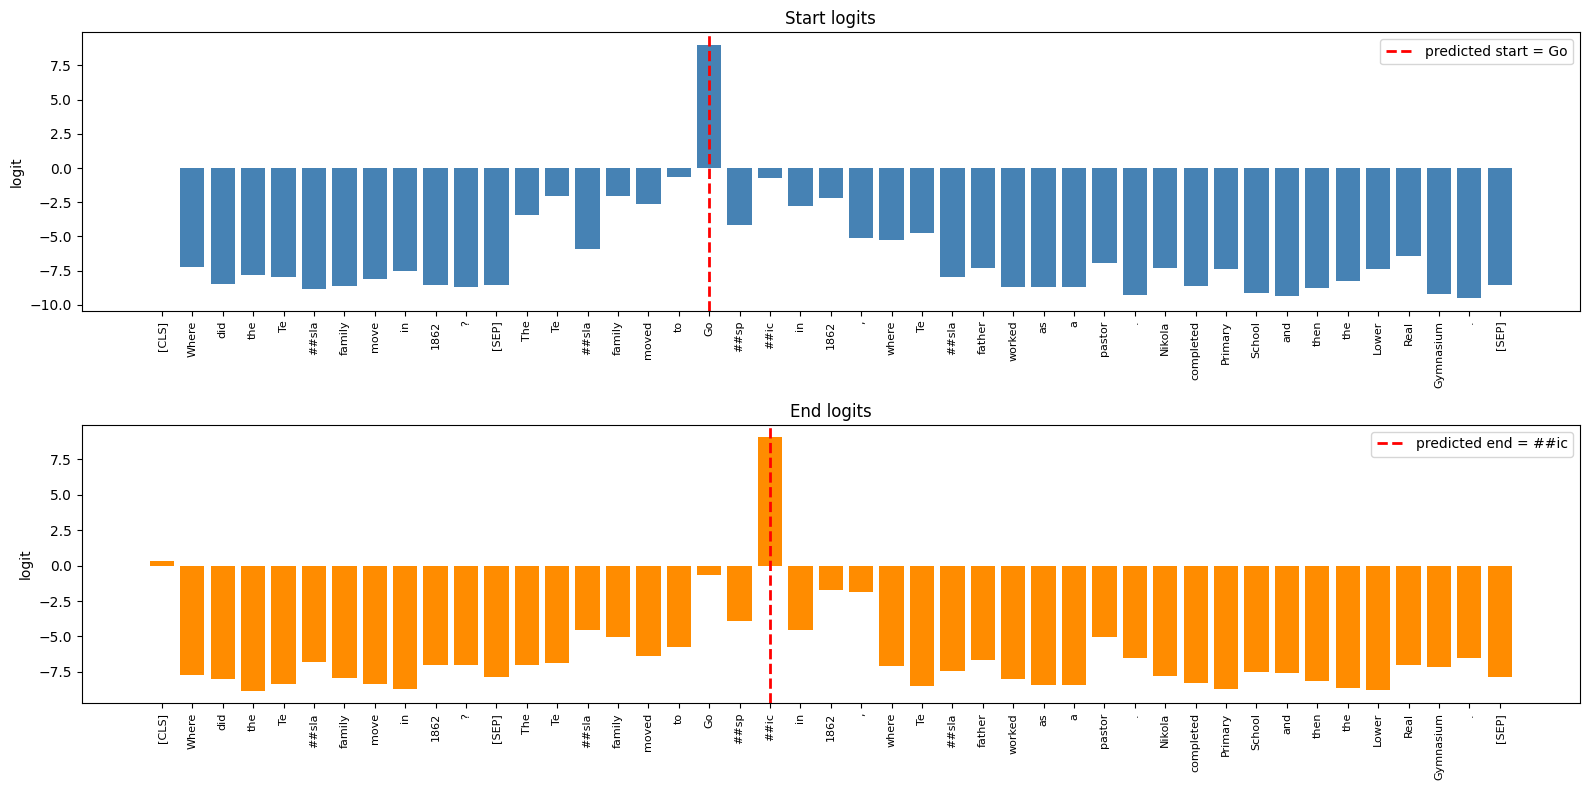

Predicted span: ['Go', '##sp', '##ic']


In [13]:
# 4.4 Visualise start / end logits for the first example
ex = squad_examples[0]
enc = tokenizer(ex['question'], ex['context'], return_tensors='pt',
                truncation='only_second', max_length=512)
seq_ids = enc.sequence_ids(0)
tokens  = tokenizer.convert_ids_to_tokens(enc['input_ids'][0])

with torch.no_grad():
    out = qa_model(**enc)
start_logits = out.start_logits[0].detach().numpy()
end_logits   = out.end_logits[0].detach().numpy()

context_idx = [i for i, sid in enumerate(seq_ids) if sid == 1]
_, pred_s, pred_e = _best_span(start_logits.tolist(), end_logits.tolist(), context_idx)
x = np.arange(len(tokens))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8))

ax1.bar(x, start_logits, color='steelblue')
ax1.axvline(pred_s, color='red', linewidth=2, linestyle='--', label=f'predicted start = {tokens[pred_s]}')
ax1.set_xticks(x); ax1.set_xticklabels(tokens, rotation=90, fontsize=8)
ax1.set_title('Start logits'); ax1.set_ylabel('logit'); ax1.legend()

ax2.bar(x, end_logits, color='darkorange')
ax2.axvline(pred_e, color='red', linewidth=2, linestyle='--', label=f'predicted end = {tokens[pred_e]}')
ax2.set_xticks(x); ax2.set_xticklabels(tokens, rotation=90, fontsize=8)
ax2.set_title('End logits'); ax2.set_ylabel('logit'); ax2.legend()

plt.tight_layout()
plt.show()
print('Predicted span:', tokens[pred_s:pred_e + 1])

### 4.5 Unanswerable Questions (SQuAD v2.0)
The model `deepset/bert-base-cased-squad2` was trained on SQuAD v2.0 which includes unanswerable questions. Run the model on the context and question below. Look at the score — what does a low/high score mean?


In [14]:
context_v2  = 'Tesla attended school in Smiljan where he studied German and arithmetic.'
question_v2 = 'What year was Tesla born?'

# Best span answer and its score
ans_v2, score_v2 = extract_answer(question_v2, context_v2, tokenizer, qa_model)

# Null ("no answer") score = start_logit[CLS] + end_logit[CLS]
enc_v2 = tokenizer(question_v2, context_v2, return_tensors='pt')
with torch.no_grad():
    out_v2 = qa_model(**enc_v2)
null_score = out_v2.start_logits[0][0].item() + out_v2.end_logits[0][0].item()

print(f"Unanswerable question : {question_v2}")
print(f"Best span answer      : '{ans_v2}'")
print(f"Span score            : {score_v2:.2f}")
print(f"Null ([CLS]) score    : {null_score:.2f}")
print(f"Decision              : {'NO ANSWER' if null_score > score_v2 else 'ANSWER EXISTS'}")

# Compare with the answerable examples from 4.3
print('\nSpan scores of the answerable examples (for comparison):')
for ex in squad_examples:
    a, s = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    print(f"  '{a}'  score = {s:.2f}")

Unanswerable question : What year was Tesla born?
Best span answer      : 'Tesla attended school in Smiljan'
Span score            : -8.62
Null ([CLS]) score    : 1.18
Decision              : NO ANSWER

Span scores of the answerable examples (for comparison):
  'Gospic'  score = 18.04
  'German, arithmetic, and religion'  score = 13.27
  '66.54'  score = 17.96


**Your answer:**

**SQuAD v1.1** guarantees that every question has an answer span inside the passage, so a model only has to pick the best start/end pair. **SQuAD v2.0** adds about 50,000 *unanswerable* questions (written adversarially so that they look similar to answerable ones, but the passage does not contain the answer). A system therefore has to decide *whether* to answer as well as *what* to answer.

**How models detect them:** the model is trained so that for unanswerable questions the correct start and end are both the `[CLS]` token (position 0). At inference the model compares the **null score** `s_null = start_logit[CLS] + end_logit[CLS]` with the **best span score** `s_span = max(start_logit[i] + end_logit[j])`. If `s_null > s_span + τ` (τ is a threshold tuned on the dev set) it predicts *no answer*; otherwise it returns the span.

**Reading the score (from our run):** for the unanswerable question *"What year was Tesla born?"* the best span (*"Tesla attended school in Smiljan"*) has a very **low score of −8.62**, while the null ([CLS]) score is **+1.18**. Since the null score is higher, the model decides **NO ANSWER**, which is correct because the passage contains no birth year. The answerable examples have **high span scores** (Gospic = 18.04, German, arithmetic, and religion = 13.27, 66.54 = 17.96), far above their null scores. So a **high span score means the model is confident the answer is in the passage, and a low (negative) span score that falls below the null score means the question should be treated as unanswerable**.

---
## Part 5: QA Evaluation — EM and F1 (15 points)

### 5.1 Implement Normalise, EM and Token F1


In [15]:
import re, string
from collections import Counter

def normalize_answer(text):
    """
    Lowercase, remove articles (a, an, the), remove punctuation, fix whitespace.
    """
    text = text.lower()
    text = re.sub(r'\b(a|an|the)\b', ' ', text)
    text = ''.join(ch for ch in text if ch not in set(string.punctuation))
    return ' '.join(text.split())

def exact_match(prediction, gold_answers):
    """
    Return 1 if prediction exactly matches any gold answer after normalisation, else 0.
    gold_answers is a list of strings.
    """
    pred_norm = normalize_answer(prediction)
    return int(any(pred_norm == normalize_answer(g) for g in gold_answers))

def token_f1(prediction, gold_answers):
    """
    Return the maximum token-level F1 over all gold answers.
    Compute precision and recall on the BAG OF WORDS of the normalised strings.
    """
    pred_tokens = normalize_answer(prediction).split()
    best_f1 = 0.0
    for gold in gold_answers:
        gold_tokens = normalize_answer(gold).split()
        if not pred_tokens and not gold_tokens:
            best_f1 = max(best_f1, 1.0)
            continue
        common = sum((Counter(pred_tokens) & Counter(gold_tokens)).values())
        if common == 0:
            continue
        precision = common / len(pred_tokens)
        recall    = common / len(gold_tokens)
        best_f1 = max(best_f1, 2 * precision * recall / (precision + recall))
    return round(best_f1, 3)

### 5.2 Evaluate on the SQuAD Examples
For each example in `squad_examples`, compute EM and F1 between your predicted answer and the gold answer. Print a table of results and average EM and F1.


In [16]:
results = []
for ex in squad_examples:
    pred, score = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    em = exact_match(pred, [ex['gold']])
    f1 = token_f1(pred, [ex['gold']])
    results.append({'question': ex['question'], 'pred': pred, 'gold': ex['gold'], 'em': em, 'f1': f1})

print(f"{'#':<3}{'Predicted':<36}{'Gold':<36}{'EM':>4}{'F1':>8}")
print('-' * 87)
for i, r in enumerate(results, 1):
    print(f"{i:<3}{r['pred']:<36}{r['gold']:<36}{r['em']:>4}{r['f1']:>8.3f}")
print('-' * 87)

avg_em = sum(r['em'] for r in results) / len(results)
avg_f1 = sum(r['f1'] for r in results) / len(results)
print(f'Average EM = {avg_em:.3f}  ({avg_em*100:.1f}%)')
print(f'Average F1 = {avg_f1:.3f}  ({avg_f1*100:.1f}%)')

# Cases with EM = 0 but F1 > 0 (used for the analysis in 5.3)
partial = [r for r in results if r['em'] == 0 and r['f1'] > 0]
print('\nExamples with EM=0 but F1>0:', 'none' if not partial else '')
for r in partial:
    print(f"  pred='{r['pred']}'  gold='{r['gold']}'  F1={r['f1']}")

#  Predicted                           Gold                                  EM      F1
---------------------------------------------------------------------------------------
1  Gospic                              Gospic                                 1   1.000
2  German, arithmetic, and religion    German, arithmetic, and religion       1   1.000
3  66.54                               66.54 percent                          0   0.667
---------------------------------------------------------------------------------------
Average EM = 0.667  (66.7%)
Average F1 = 0.889  (88.9%)

Examples with EM=0 but F1>0: 
  pred='66.54'  gold='66.54 percent'  F1=0.667


### 5.3 Analysis
For any example where EM=0 but F1>0, explain in a markdown cell **why** EM is stricter than F1 and whether the model's answer is actually reasonable.


**Your analysis:**

In our run, example 3 has **EM = 0 but F1 = 0.667**: the model predicted **"66.54"** while the gold answer is **"66.54 percent"**.

**Why EM is stricter:** Exact Match gives credit only if the normalised prediction is *identical* to a gold answer. After normalisation `"66.54"` ≠ `"66.54 percent"`, so EM = 0 even though the number is right. **Token F1** works on the bag of words: the prediction has 1 token and the gold has 2, with 1 token in common, so precision = 1/1 = 1.0, recall = 1/2 = 0.5 and F1 = 2·1.0·0.5/(1.0+0.5) = **0.667**. F1 therefore gives partial credit for the overlap.

**Is the answer reasonable?** Yes. The model found the correct value (66.54) and only left out the unit word *"percent"*, which is already implied by the question ("What percentage…"). A human would accept it, so EM under-rates the answer. This is why SQuAD reports both metrics. Overall: average EM = 0.667 (66.7%) and average F1 = 0.889 (88.9%).

---
## Part 6: Open-Domain QA Pipeline (10 points)

In reading comprehension, the passage is given. In open-domain QA, we must first **retrieve** relevant passages.

### 6.1 Implement a Simple BM25-style Retriever
Given a small corpus of documents and a query, implement `bm25_retrieve(query, corpus, k=3)` that returns the top-k documents using **TF-IDF** scoring (using `sklearn.feature_extraction.text.TfidfVectorizer`).


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

CORPUS = [
    'Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.',
    'Nikola Tesla was a Serbian-American inventor known for his work on alternating current electricity.',
    'Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.',
    'The Eiffel Tower is located in Paris and was constructed between 1887 and 1889.',
    'Python is a high-level programming language created by Guido van Rossum in 1991.',
    'The Amazon rainforest produces 20 percent of the worlds oxygen and spans 9 countries.',
    'Albert Einstein developed the theory of relativity and won the 1921 Nobel Prize in Physics.',
    'The Great Wall of China was built over many centuries to protect Chinese states from invasions.',
]

def bm25_retrieve(query, corpus, k=3):
    """
    Retrieve top-k documents most relevant to the query using TF-IDF.
    Returns: list of (score, document_string), sorted by score descending
    """
    from sklearn.metrics.pairwise import cosine_similarity
    vectorizer = TfidfVectorizer(stop_words='english')
    doc_vecs = vectorizer.fit_transform(corpus)          # vectorize the corpus
    q_vec    = vectorizer.transform([query])             # vectorize the query
    sims     = cosine_similarity(q_vec, doc_vecs).flatten()
    top_k    = np.argsort(-sims)[:k]                     # indices of the k best documents
    return [(float(sims[i]), corpus[i]) for i in top_k]

# Quick check
for score, doc in bm25_retrieve('Where was Barack Obama born?', CORPUS, k=3):
    print(f'{score:.3f}  {doc}')

0.577  Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.
0.000  Nikola Tesla was a Serbian-American inventor known for his work on alternating current electricity.
0.000  Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.


### 6.2 Build the Full Retriever-Reader Pipeline
Implement `open_domain_qa(question, corpus, retriever, reader_fn, k=3)` that:
1. Retrieves the top-k passages using `retriever`.
2. Runs `reader_fn` (your `extract_answer`) on each passage.
3. Returns the answer with the highest score.


In [18]:
def open_domain_qa(question, corpus, retriever, reader_fn, k=3):
    """
    Arguments:
        question:   str
        corpus:     list of str
        retriever:  callable(query, corpus, k) → list of (score, doc)
        reader_fn:  callable(question, context) → (answer, score)
        k:          number of passages to retrieve
    Returns:
        best_answer: str
        best_score:  float
    """
    retrieved = retriever(question, corpus, k)           # 1. retrieve top-k passages
    best_answer, best_score = '', float('-inf')
    for ret_score, passage in retrieved:                 # 2. read every passage
        answer, qa_score = reader_fn(question, passage)
        if qa_score > best_score:                        # 3. keep the highest-scoring answer
            best_answer, best_score = answer, qa_score
    return best_answer, best_score

# Test it
test_questions = [
    'Where was Barack Obama born?',
    'Who discovered radium?',
    'When was the Eiffel Tower built?',
]
reader = lambda q, c: extract_answer(q, c, tokenizer, qa_model)

for q in test_questions:
    answer, score = open_domain_qa(q, CORPUS, bm25_retrieve, reader, k=3)
    print(f'Q: {q}')
    print(f'   Retrieved: {[round(s, 3) for s, _ in bm25_retrieve(q, CORPUS, 3)]}')
    print(f'   Answer   : {answer}   (score = {score:.2f})')
    print()

Q: Where was Barack Obama born?
   Retrieved: [0.577, 0.0, 0.0]
   Answer   : Hawaii   (score = 15.28)

Q: Who discovered radium?
   Retrieved: [0.488, 0.0, 0.0]
   Answer   : Curie   (score = -3.57)

Q: When was the Eiffel Tower built?
   Retrieved: [0.436, 0.192, 0.0]
   Answer   : between 1887 and 1889   (score = 9.79)



### 6.3 Short Answer
Explain in 3–4 lines why **dense retrieval (DPR)** can find relevant passages that BM25 might miss. Give a concrete example.


**Your answer:**

BM25/TF-IDF can only match passages that share the **exact words** (or stems) with the question, so it fails on vocabulary mismatch. **Dense retrieval (DPR)** encodes the question and the passages with BERT encoders into the same vector space and ranks by dot-product similarity, so passages with the same *meaning* are close even without word overlap. Example: the question *"Who invented the telephone?"* and the passage *"Alexander Graham Bell patented the first practical device for transmitting speech electrically"* share no keywords (BM25 gives ≈ 0), but DPR places them close together because *invented / patented* and *telephone / device for transmitting speech* are semantically related. DPR is also trained end-to-end on question-passage pairs, which makes it more robust to paraphrases and synonyms.

---
## Part 7: Connecting Coreference and Question Answering (5 points)

### 7.1 Coref-Aided QA
Consider the passage below where coreference is **required** to answer the question correctly.


In [19]:
coref_passage = (
    'Maria was the top student in her class. '
    'She won the national science prize in 2023. '
    'The award was presented to her by the Prime Minister.'
)
coref_question = 'Who won the national science prize?'

# Step 1: Run coreference resolution on the passage
coref_pred = model.predict(texts=[coref_passage])[0]
print('Step 1 — Coreference clusters:')
for cluster in coref_pred.get_clusters(as_strings=True):
    print('  ', ' → '.join(cluster))

# Step 2: Run QA directly on the passage
ans_raw, score_raw = extract_answer(coref_question, coref_passage, tokenizer, qa_model)
print('\nStep 2 — QA on the ORIGINAL passage:')
print(f"  Q: {coref_question}")
print(f"  A: '{ans_raw}'   (score = {score_raw:.2f})")

# Step 3: Show how resolving 'She' → 'Maria' helps answer correctly
resolved_passage = coref_passage.replace('She won', 'Maria won').replace(' her by', ' Maria by')
print('\nStep 3 — Resolved passage:')
print(' ', resolved_passage)
ans_res, score_res = extract_answer(coref_question, resolved_passage, tokenizer, qa_model)
print('\n  QA on the RESOLVED passage:')
print(f"  A: '{ans_res}'   (score = {score_res:.2f})")

print('\nComparison:')
print(f"  Without coref: '{ans_raw}' (score {score_raw:.2f})")
print(f"  With coref   : '{ans_res}' (score {score_res:.2f})")

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

Step 1 — Coreference clusters:
   Maria → her → She → her
   the national science prize → The award

Step 2 — QA on the ORIGINAL passage:
  Q: Who won the national science prize?
  A: 'She won the national science prize in 2023'   (score = -5.19)

Step 3 — Resolved passage:
  Maria was the top student in her class. Maria won the national science prize in 2023. The award was presented to Maria by the Prime Minister.

  QA on the RESOLVED passage:
  A: 'Maria won the national science prize in 2023. The award was presented to Maria'   (score = -0.52)

Comparison:
  Without coref: 'She won the national science prize in 2023' (score -5.19)
  With coref   : 'Maria won the national science prize in 2023. The award was presented to Maria' (score -0.52)


### 7.2 Reflection
In 4–5 sentences, explain:
1. Why coreference resolution can improve QA performance.
2. Give a type of question where coref is **essential** (not just helpful).
3. What challenges remain even after combining coref + QA?


**Your reflection:**

Coreference resolution improves QA because the sentence that contains the answer often refers to the entity through a pronoun. In our run, QA on the original passage returned the span *"She won the national science prize in 2023"* (score −5.19), which does not actually name the winner, because the entity is only mentioned as the pronoun *She*. After resolving *She → Maria* (the coref model correctly clustered *Maria → her → She → her*), the extracted span contains *Maria* explicitly (*"Maria won the national science prize in 2023. The award was presented to Maria"*) and the score improves to −0.52, so the answer now names the person. Coref is **essential** (not just helpful) for questions whose answer appears only through a pronoun or a later description, for example *"Who was awarded the prize by the Prime Minister?"* or *"Where did he study?"*, because no single sentence contains both the entity name and the requested fact. Challenges remain: coref errors propagate into QA (a wrong link gives a wrong answer), the model still extracted an overly long, low-confidence span, ambiguous same-gender antecedents and nested mentions are still hard, running two models is slower, and bridging, event coreference and world-knowledge reasoning go beyond what a coreference model resolves.